# Busca híbrida de produtos de moda

Este notebook reúne a implementação do experimento do TCC. O objetivo é comparar a busca por similaridade textual com duas variantes que aplicam filtros extraídos por um modelo de linguagem antes do ranking.

| Sistema | Candidatos | Texto usado no ranking |
| :--- | :--- | :--- |
| Linha de base (`baseline`) | Catálogo completo | Consulta completa |
| Filtros + consulta completa (`filters_full`) | Produtos que atendem aos filtros aplicados | Consulta completa |
| Filtros + residual (`filters_soft`) | Produtos que atendem aos filtros aplicados | Consulta com remoção determinística de evidências de uma palavra |

Os sistemas compartilham o mesmo catálogo e, para cada encoder, os mesmos vetores de produtos. A avaliação separa a recuperação do artigo de origem, a conformidade com atributos e a extração de restrições.

**Organização:** ambiente e configuração; catálogo e vocabulário; extração e busca; consultas e avaliação; execução e resultados. O apêndice conserva as tabelas e figuras que já estavam no arquivo recebido.

## 1. Ambiente de execução

O experimento foi preparado para o Google Colab com GPU. Antes de executar:

1. Selecione um ambiente com GPU; a execução registrada no TCC usou uma T4.
2. Disponibilize `articles.csv` no diretório do notebook. Se o arquivo não estiver lá, o código tenta baixá-lo da competição H&M no Kaggle.
3. Para o download, aceite as condições da competição na sua conta e configure `KAGGLE_API_TOKEN` nos segredos do Colab ou nas variáveis de ambiente.
4. Execute as células em ordem. As etapas salvam o progresso em `tcc_validacao`.

As dependências abaixo seguem a instalação do notebook original, sem versões fixadas. Cada execução registra as versões efetivamente instaladas em `requirements_observed.txt`; para reproduzir o ambiente de uma rodada, consulte esse registro.

In [ ]:
%pip install -q sentence-transformers transformers accelerate kaggle numpy pandas matplotlib tqdm

## 2. Como o código é executado

As próximas células escrevem as partes do arquivo `tcc_validacao_worker.py`. A primeira cria o arquivo; as demais acrescentam as definições seguintes. Por isso, execute a primeira célula antes de repetir as demais.

Esse arquivo é executado em processos separados: preparação, geração das consultas, extração dos filtros, MiniLM, BGE e consolidação. Assim, cada modelo libera a memória quando sua etapa termina. As células de definição não carregam os modelos no processo principal do notebook.

## 3. Configuração e funções de apoio

A configuração mantém 10.000 produtos, 200 consultas sintéticas, 40 consultas de atributos e as sementes 42 e 2026. `TOP_K = 5` se aplica aos testes de atributos; a recuperação sintética é avaliada até a posição 20.

MiniLM e BGE fazem o ranking. Qwen2.5-3B gera as consultas e Qwen2.5-1.5B extrai os filtros. O uso de modelos distintos da mesma família não garante independência entre geração e extração.

O filtro de público permanece desativado, e o rótulo `Top` recebe abstenção. Ao mudar os parâmetros ou a política experimental, use uma pasta de saída nova, para separar as rodadas.

In [ ]:
%%writefile tcc_validacao_worker.py

"""Busca de produtos de moda: linha de base densa e duas variantes híbridas."""

import os
import json
import re
import time
import html
import base64
from dataclasses import dataclass, field, asdict
from pathlib import Path
import hashlib
import gc
import subprocess
import sys
import platform
import shutil
import builtins
import resource

import numpy as np
import pandas as pd
import torch
from IPython.display import HTML, display
from sentence_transformers import SentenceTransformer
from transformers import pipeline
from tqdm.auto import tqdm


SEED = 42
SAMPLE_SIZE = 10_000
TOP_K = 5
# Rótulos muito raros ficam fora do vocabulário de filtros.
MIN_VALUE_COUNT = 5
EMBEDDER_NAMES = ['all-MiniLM-L6-v2', 'BAAI/bge-small-en-v1.5']
PARSER_MODEL = 'Qwen/Qwen2.5-1.5B-Instruct'
QUERY_GENERATOR_MODEL = 'Qwen/Qwen2.5-3B-Instruct'
N_SYNTHETIC = 200
VALIDATION_SEED = 2026
PREVIOUS_OUT = Path('tcc_outputs_v3')
# O termo 'top' também pode indicar 'Vest top' no catálogo.
AMBIGUOUS_PRODUCT_TYPES = {'Top'}
# O campo de público mistura grupos como Sport e Divided.
USE_AUDIENCE_FILTER = False
OUT = Path('tcc_validacao')
OUT.mkdir(parents=True, exist_ok=True)
# Só os embeddings são reaproveitados da pasta do piloto.
for old in PREVIOUS_OUT.glob('embeddings_*.npy'):
    if not (OUT / old.name).exists():
        shutil.copyfile(old, OUT / old.name)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
if DEVICE == 'cpu':
    raise RuntimeError('GPU unavailable. Select a GPU in Colab before running the experiment.')
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)


def stable_hash(value):
    """Identifica os dados e as configurações usados nos arquivos de cache."""
    return hashlib.sha256(json.dumps(
        value,
        sort_keys=True,
        ensure_ascii=False,
        default=str,
    ).encode()).hexdigest()


def atomic_json(path, value):
    """Substitui o JSON somente depois de gravar o arquivo temporário."""
    path = Path(path)
    temp = path.with_suffix(path.suffix + '.tmp')
    temp.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False))
    temp.replace(path)


def gpu_sync():
    """Espera a GPU terminar as operações antes de medir o tempo."""
    if torch.cuda.is_available():
        torch.cuda.synchronize()


def memory_status(stage):
    """Registra o uso de memória da etapa no arquivo de acompanhamento."""
    try:
        pages = int(Path('/proc/self/statm').read_text().split()[1])
        rss_mb = pages * os.sysconf('SC_PAGE_SIZE') / 1024 ** 2
    except (OSError, ValueError, IndexError):
        rss_mb = None
    record = {
        'stage': stage,
        'pid': os.getpid(),
        'rss_mb': rss_mb,
        'peak_rss_mb': resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024,
    }
    if torch.cuda.is_available():
        record['gpu_allocated_mb'] = torch.cuda.memory_allocated() / 1024 ** 2
    with (OUT / 'memory_trace.jsonl').open('a') as f:
        f.write(json.dumps(record) + '\n')
    print('Memory:', record, flush=True)
FILTER_FIELDS = ['colour_family', 'index_group_name', 'product_type_name']
UNINFORMATIVE_VALUES = {'Unknown', 'Other', 'Unmapped'}
SYNONYMS = {
    'product_type_name': {
        'jeans': 'Trousers',
        'pants': 'Trousers',
        'boot': 'Boots',
        'tee': 'T-shirt',
        'tshirt': 'T-shirt',
        't shirt': 'T-shirt',
    },
    'colour_family': {'gray': 'Grey', 'navy': 'Blue'},
    'index_group_name': {
        'women': 'Ladieswear',
        'woman': 'Ladieswear',
        'womens': 'Ladieswear',
        "women's": 'Ladieswear',
        'ladies': 'Ladieswear',
        'female': 'Ladieswear',
        'men': 'Menswear',
        'man': 'Menswear',
        'mens': 'Menswear',
        "men's": 'Menswear',
        'male': 'Menswear',
        'kids': 'Baby/Children',
        'kid': 'Baby/Children',
        'children': 'Baby/Children',
        'child': 'Baby/Children',
        'baby': 'Baby/Children',
    },
}

Writing tcc_validacao_worker.py


## 4. Preparação do catálogo

Os artigos sem descrição são retirados antes da amostragem. O texto dos produtos reúne nome, tipo, categoria, cor, público e descrição, e é o mesmo para os três sistemas.

As cores são agrupadas por uma tabela explícita. Valores fora desse mapeamento recebem `Unmapped` e não entram no vocabulário de filtros.

In [ ]:
%%writefile -a tcc_validacao_worker.py

if not Path('articles.csv').exists():
    if not os.environ.get('KAGGLE_API_TOKEN'):
        raise RuntimeError('Kaggle token missing. Run the notebook launcher to configure it.')
    subprocess.run(
        [
            'kaggle',
            'competitions',
            'download',
            '-c',
            'h-and-m-personalized-fashion-recommendations',
            '-f',
            'articles.csv',
        ],
        check=True,
    )
    import zipfile
    with zipfile.ZipFile('articles.csv.zip') as z:
        z.extract('articles.csv', '.')
# As famílias de cor são uma convenção do experimento, não tons exatos.
COLOR_GROUPS = {
    'Black': ['Black'],
    'White': ['White', 'Off White'],
    'Grey': ['Grey', 'Light Grey', 'Dark Grey', 'Greyish Grey'],
    'Blue': ['Blue', 'Light Blue', 'Dark Blue', 'Greenish Blue'],
    'Turquoise': ['Turquoise', 'Light Turquoise', 'Dark Turquoise'],
    'Red': ['Red', 'Dark Red'],
    'Pink': ['Pink', 'Light Pink', 'Dark Pink'],
    'Purple': ['Purple', 'Light Purple', 'Dark Purple', 'Lilac Purple'],
    'Orange': ['Orange', 'Light Orange', 'Pinkish Orange'],
    'Yellow': ['Yellow', 'Light Yellow'],
    'Brown': ['Brown', 'Light Brown', 'Dark Brown', 'Yellowish Brown'],
    'Beige': ['Beige', 'Light Beige', 'Dark Beige'],
    'Green': ['Green', 'Light Green', 'Dark Green', 'Greenish Khaki', 'Yellowish Green'],
}
COLOR_MAP = {raw: family for family, names in COLOR_GROUPS.items() for raw in names}
COLOR_MAP.update({
    'Dark Orange': 'Orange',
    'Dark Yellow': 'Yellow',
    'Light Red': 'Red',
    'Greyish Beige': 'Beige',
    'Other Blue': 'Blue',
    'Other Green': 'Green',
    'Other Orange': 'Orange',
    'Other Pink': 'Pink',
    'Other Purple': 'Purple',
    'Other Red': 'Red',
    'Other Turquoise': 'Turquoise',
    'Other Yellow': 'Yellow',
})


def load_catalog():
    """Lê os artigos, retira descrições ausentes e seleciona a amostra do catálogo."""
    articles = pd.read_csv('articles.csv')
    # Cores sem correspondência explícita permanecem como Unmapped.
    articles['colour_family'] = articles['colour_group_name'].map(COLOR_MAP).fillna('Unmapped')
    with_description = articles.dropna(subset=['detail_desc'])
    print(f'\nTotal articles in CSV:       {len(articles):,}')
    print(f'Missing description (dropped): {len(articles) - len(with_description):,}')
    print(f'With description:            {len(with_description):,}')
    catalog = with_description.sample(SAMPLE_SIZE, random_state=SEED).reset_index(drop=True)
    print(f'Experimental catalog size:   {len(catalog):,} (seed={SEED})\n')
    catalog['text_for_embedding'] = (
        'Name: ' + catalog['prod_name'].fillna('') + '. '
        + 'Type: ' + catalog['product_type_name'].fillna('') + '. '
        + 'Category: ' + catalog['product_group_name'].fillna('') + '. '
        + 'Color: ' + catalog['colour_group_name'].fillna('') + '. '
        + 'Audience: ' + catalog['index_group_name'].fillna('') + '. '
        + 'Description: ' + catalog['detail_desc']
    )
    return (articles, catalog)

Appending to tcc_validacao_worker.py


## 5. Análise dos rótulos e vocabulário

A análise de frequências descreve os campos do catálogo completo. Já o vocabulário permitido ao parser é construído sobre a amostra experimental: valores com menos de cinco ocorrências e rótulos sem informação útil são excluídos.

In [ ]:
%%writefile -a tcc_validacao_worker.py

CANDIDATE_FIELDS = [
    'product_type_name',
    'colour_group_name',
    'colour_family',
    'index_group_name',
    'garment_group_name',
    'section_name',
]


def analyze_label_space(df, fields=CANDIDATE_FIELDS, out_dir='label_space'):
    """Salva a frequência dos rótulos e resume os campos disponíveis."""
    os.makedirs(out_dir, exist_ok=True)
    rows = []
    for name in fields:
        counts = df[name].value_counts()
        counts.rename_axis(name).rename('n_articles').to_csv(f'{out_dir}/{name}.csv')
        rows.append({
            'field': name,
            'distinct_values': len(counts),
            'values_below_min_count': int((counts < MIN_VALUE_COUNT).sum()),
            'top5_coverage': round(counts.head(5).sum() / counts.sum(), 3),
            'missing': int(df[name].isna().sum()),
        })
    summary = pd.DataFrame(rows)
    return summary


def build_vocabulary(df, fields=FILTER_FIELDS):
    """Seleciona os valores frequentes e informativos de cada campo."""
    vocabulary = {}
    for name in fields:
        counts = df[name].value_counts()
        values = [v for v, n in counts.items() if n >= MIN_VALUE_COUNT and v not in UNINFORMATIVE_VALUES]
        vocabulary[name] = sorted(values)
    return vocabulary

Appending to tcc_validacao_worker.py


## 6. Extração e validação das restrições

O parser recebe a consulta, o vocabulário e quatro exemplos de desenvolvimento. Para cada filtro, deve retornar o valor e um trecho de evidência. Os prompts e os exemplos em inglês foram mantidos como no experimento original.

O validador confere o vocabulário e a presença da evidência, com um ajuste restrito de sinônimos. Essa checagem não assegura que o trecho sustente semanticamente o filtro. Também foi mantido o comportamento de `json.loads` diante de chaves repetidas: prevalece o último valor, limitação discutida no TCC.

O campo `soft_intent` é salvo para inspeção. O ranking residual usa a função determinística definida na próxima seção.

In [ ]:
%%writefile -a tcc_validacao_worker.py

@dataclass
class ParsedQuery:
    """Guarda os filtros extraídos, as evidências e os valores descartados."""
    query: str
    filters: dict = field(default_factory=dict)
    soft_intent: str = ''
    dropped: list = field(default_factory=list)
    ok: bool = True
    llm_seconds: float = 0.0
    raw_response: str = ''
    evidence: dict = field(default_factory=dict)


def is_empty(value):
    return value is None or str(value).strip().lower() in {'', 'null', 'none', 'n/a'}


class QueryParser:
    """Extrai restrições da consulta e confere os valores no vocabulário."""

    def __init__(self, vocabulary, model_name=PARSER_MODEL):
        self.vocab = vocabulary
        self.lookup = {name: {v.lower(): v for v in values} for name, values in vocabulary.items()}
        # O modelo só é carregado quando a consulta ainda não está no cache.
        self.pipe = None
        self.model_name = model_name
        self.base_messages = self._build_base_messages()
        self.fingerprint = stable_hash({
            'model': model_name,
            'messages': self.base_messages,
            'synonyms': SYNONYMS,
            'validator': 'evidence-alias-alignment-v4',
        })
        self.cache_path = OUT / ('parser_' + self.fingerprint[:16] + '.json')
        self.cache = json.loads(self.cache_path.read_text()) if self.cache_path.exists() else {}

    def _build_base_messages(self):
        vocab = json.dumps(self.vocab, ensure_ascii=False)
        system = """Extract explicitly stated fashion constraints. Return JSON only.
Schema: {"filters": {"product_type_name": null, "colour_family": null,
"index_group_name": null}, "evidence": {}, "soft_intent": "remaining query words"}.
Each non-null value MUST be from the allowed vocabulary and have evidence:
an exact contiguous quotation from the user's query supporting that field.
Never infer audience from garment, occasion or style. Never infer colour from style.
Use null when unspecified or ambiguous. Preserve garment/style details in soft_intent
if they cannot be represented by an exact allowed filter. An evidence quote must
support the chosen value, not merely occur in the query.
Allowed vocabulary: """ + vocab
        examples = [
            (
                'formal red trousers for a gala',
                {'product_type_name': 'Trousers', 'colour_family': 'Red'},
                {'product_type_name': 'trousers', 'colour_family': 'red'},
                'formal for a gala',
            ),
            (
                'goth white maxi dress',
                {'product_type_name': 'Dress', 'colour_family': 'White'},
                {'product_type_name': 'dress', 'colour_family': 'white'},
                'goth maxi',
            ),
            ('something cozy for winter', {}, {}, 'something cozy for winter'),
            (
                "men's white sneakers",
                {
                    'product_type_name': 'Sneakers',
                    'colour_family': 'White',
                    'index_group_name': 'Menswear',
                },
                {
                    'product_type_name': 'sneakers',
                    'colour_family': 'white',
                    'index_group_name': "men's",
                },
                '',
            ),
        ]
        # Os exemplos do prompt pertencem ao desenvolvimento, não ao teste.
        messages = [{'role': 'system', 'content': system}]
        for query, filters, evidence, soft in examples:
            answer = {
                'filters': {k: filters.get(k) for k in FILTER_FIELDS},
                'evidence': evidence,
                'soft_intent': soft,
            }
            messages += [
                {'role': 'user', 'content': query},
                {'role': 'assistant', 'content': json.dumps(answer)},
            ]
        return messages

    def normalize(self, field_name, raw):
        if not isinstance(raw, str):
            return None
        key = raw.strip().lower()
        key = SYNONYMS.get(field_name, {}).get(key, key).lower()
        return self.lookup[field_name].get(key)

    def parse(self, query):
        key = stable_hash(query)
        if key in self.cache:
            return ParsedQuery(**self.cache[key])
        if self.pipe is None:
            memory_status('before_parser_load')
            self.pipe = pipeline(
                'text-generation',
                model=self.model_name,
                dtype=torch.float16,
                device_map={'': 0},
                model_kwargs={'low_cpu_mem_usage': True},
            )
        if self.pipe.model.dtype != torch.float16:
            raise RuntimeError('Unexpected parser dtype; refusing an unplanned model precision')
        gpu_sync()
        start = time.perf_counter()
        output = self.pipe(
            self.base_messages + [{'role': 'user', 'content': query}],
            max_new_tokens=220,
            do_sample=False,
        )
        gpu_sync()
        elapsed = time.perf_counter() - start
        text = output[0]['generated_text'][-1]['content'].strip()
        parsed = self._validate(query, text, elapsed)
        self.cache[key] = asdict(parsed)
        atomic_json(self.cache_path, self.cache)
        return parsed

    def _validate(self, query, text, seconds):
        parsed = ParsedQuery(query=query, raw_response=text, llm_seconds=seconds)
        try:
            match = re.search('\\{.*\\}', text, re.DOTALL)
            data = json.loads(match.group(0))
            if not isinstance(data, dict):
                raise ValueError('Expected object')
            raw_filters = data.get('filters')
            evidence = data.get('evidence')
            soft = data.get('soft_intent', '')
            if (
                not isinstance(raw_filters, dict)
                or not isinstance(evidence, dict)
                or not isinstance(soft, str)
            ):
                raise ValueError('Invalid schema')
        except (AttributeError, TypeError, ValueError, json.JSONDecodeError):
            parsed.ok = False
            return parsed
        for name in FILTER_FIELDS:
            raw = raw_filters.get(name)
            if is_empty(raw):
                continue
            value = self.normalize(name, raw)
            quote = evidence.get(name)
            grounded = isinstance(quote, str) and bool(quote.strip()) and bool(re.search(
                '(?<!\\w)' + re.escape(quote.strip()) + '(?!\\w)',
                query,
                re.I,
            ))
            # Ajusta boot/boots apenas se o sinônimo levar ao mesmo valor do campo.
            if value is not None and isinstance(quote, str) and (not grounded):
                if self.normalize(name, quote) == value:
                    aliases = [v for v in self.lookup[name].values() if v == value]
                    aliases += [
                        alias
                        for alias, canonical in SYNONYMS.get(name, {}).items()
                        if canonical.casefold() == value.casefold()
                    ]
                    for alias in sorted(aliases, key=len, reverse=True):
                        match = re.search('(?<!\\w)' + re.escape(alias) + '(?!\\w)', query, re.I)
                        if match:
                            quote = match.group(0)
                            grounded = True
                            break
            if value is None or not grounded:
                parsed.dropped.append((name, raw, 'invalid_value_or_evidence'))
                continue
            parsed.filters[name] = value
            parsed.evidence[name] = quote
        # A ocorrência da evidência no texto não garante que ela apoie o filtro.
        parsed.soft_intent = soft.strip()
        return parsed

Appending to tcc_validacao_worker.py


## 7. Sistemas de busca

Os vetores são normalizados e comparados por produto escalar exato. A ordenação estável preserva a ordem dos candidatos em empates de pontuação.

O híbrido aplica todos os filtros aceitos pela política e pode retornar menos de `k` produtos. Se a resposta do parser for inválida, a consulta segue pela linha de base. Na variante residual, somente evidências de uma palavra ligadas a filtros efetivamente aplicados são removidas. Se a remoção esvaziar o texto, a consulta original é mantida.

In [ ]:
%%writefile -a tcc_validacao_worker.py

CATALOG_COLUMNS = [
    'article_id',
    'prod_name',
    'product_type_name',
    'colour_group_name',
    'colour_family',
    'index_group_name',
    'detail_desc',
]


@dataclass
class SearchResult:
    """Reúne os produtos recuperados e os registros da busca."""
    results: pd.DataFrame
    method: str
    n_candidates: int
    candidate_idx: np.ndarray = None
    filters_used: dict = field(default_factory=dict)
    filters_abstained: dict = field(default_factory=dict)
    filters_dropped: list = field(default_factory=list)
    parse_ok: bool = True
    fell_back: bool = False
    seconds: dict = field(default_factory=lambda: {'llm': 0.0, 'filter': 0.0, 'rank': 0.0})

    @property
    def relaxed(self):
        return bool(self.filters_dropped)


def residual_from_evidence(query, applied_filters, evidence):
    """Retira evidências de uma palavra ligadas aos filtros aplicados.

    Trechos com mais de uma palavra são mantidos, pois podem conter detalhes
    de material ou estilo. Se a remoção esvaziar a consulta, usa o texto original.
    """
    residual = query
    for name in applied_filters:
        quote = evidence.get(name)
        if not isinstance(quote, str) or not quote.strip() or len(quote.split()) != 1:
            continue
        residual = re.sub(
            '(?<!\\w)' + re.escape(quote.strip()) + '(?!\\w)',
            ' ',
            residual,
            flags=re.I,
        )
    residual = re.sub('\\s+', ' ', residual).strip(' ,.;:-')
    return residual if re.search('\\w', residual) else query


class Retriever:
    """Executa a busca densa e o ranking dos candidatos após a filtragem."""

    def __init__(self, catalog, embedder_name, parser):
        self.catalog = catalog
        self.parser = parser
        self.embedder_name = embedder_name
        self.embedder = SentenceTransformer(embedder_name, device=DEVICE)
        self.row_of = dict(builtins.zip(catalog['article_id'], catalog.index))
        print(f'Generating embeddings with {embedder_name}...')
        fingerprint = stable_hash({
            'model': embedder_name,
            'normalization': True,
            'items': catalog[['article_id', 'text_for_embedding']].to_dict('records'),
        })
        path = OUT / ('embeddings_' + fingerprint[:16] + '.npy')
        if path.exists():
            self.embeddings = np.load(path, mmap_mode='r')
        else:
            self.embeddings = self.embedder.encode(
                catalog['text_for_embedding'].tolist(),
                batch_size=16,
                show_progress_bar=True,
                normalize_embeddings=True,
            )
            np.save(path, self.embeddings)
        self.query_cache = {}

    def _rank(self, text, candidate_idx, top_k):
        if len(candidate_idx) == 0:
            ranked = self.catalog.iloc[[]][CATALOG_COLUMNS].copy()
            ranked['similarity_score'] = pd.Series(dtype=float)
            return ranked
        # O prefixo de consulta é aplicado somente ao encoder BGE.
        prefix = (
            'Represent this sentence for searching relevant passages: '
            if 'bge-' in self.embedder_name else ''
        )
        key = prefix + text
        if key not in self.query_cache:
            self.query_cache[key] = self.embedder.encode(key, normalize_embeddings=True)
        scores = self.embeddings[candidate_idx] @ self.query_cache[key]
        best = np.argsort(-scores, kind='stable')[:top_k]
        ranked = self.catalog.iloc[candidate_idx[best]][CATALOG_COLUMNS].copy()
        ranked['similarity_score'] = scores[best]
        return ranked.reset_index(drop=True)

    def baseline_search(self, query, top_k=TOP_K):
        everything = np.arange(len(self.catalog))
        start = time.perf_counter()
        ranked = self._rank(query, everything, top_k)
        result = SearchResult(ranked, 'baseline', len(everything), candidate_idx=everything)
        result.seconds['rank'] = time.perf_counter() - start
        return result

    def _filter(self, filters):
        # Os filtros não são relaxados para completar a quantidade de resultados.
        active = {
            k: v
            for k, v in filters.items()
            if (USE_AUDIENCE_FILTER or k != 'index_group_name')
            and not (k == 'product_type_name' and v in AMBIGUOUS_PRODUCT_TYPES)
        }
        mask = np.ones(len(self.catalog), dtype=bool)
        for name, value in active.items():
            mask &= (self.catalog[name] == value).to_numpy()
        return (np.flatnonzero(mask), active, [])

    def hybrid_search(self, query, top_k=TOP_K, parsed=None, rank_with='soft_intent'):
        parsed = parsed or self.parser.parse(query)
        if not parsed.ok:
            result = self.baseline_search(query, top_k)
            result.method, result.parse_ok, result.fell_back = ('hybrid', False, True)
            result.seconds['llm'] = parsed.llm_seconds
            return result
        start = time.perf_counter()
        candidates, used, dropped = self._filter(parsed.filters)
        filter_seconds = time.perf_counter() - start
        # O residual é calculado pelas evidências; não usa o soft_intent do LLM.
        residual = residual_from_evidence(query, used, parsed.evidence)
        rank_text = residual if rank_with == 'soft_intent' else query
        start = time.perf_counter()
        ranked = self._rank(rank_text, candidates, top_k)
        rank_seconds = time.perf_counter() - start
        result = SearchResult(
            ranked,
            'hybrid',
            len(candidates),
            candidate_idx=candidates,
            filters_used=used,
            filters_dropped=dropped,
            filters_abstained={k: v for k, v in parsed.filters.items() if k not in used},
        )
        result.seconds = {'llm': parsed.llm_seconds, 'filter': filter_seconds, 'rank': rank_seconds}
        return result


def compare_systems(retriever, query, top_k=TOP_K):
    """Compara a linha de base com o híbrido que usa a consulta residual."""
    return (retriever.baseline_search(query, top_k), retriever.hybrid_search(query, top_k))

Appending to tcc_validacao_worker.py


## 8. Consultas de atributos

As 40 consultas abaixo verificam combinações de tipo e cor, restrições de apenas um campo e pedidos sem atributos explícitos. Os rótulos foram propostos para o estudo e não constituem julgamentos independentes de relevância.

Há 34 consultas com alguma restrição e seis sem restrições. Nenhuma usa público como rótulo esperado.

In [ ]:
%%writefile -a tcc_validacao_worker.py

ANNOTATED_QUERIES = [
    {
        'query': 'white sneakers for everyday walking',
        'expected': {
            'product_type_name': 'Sneakers',
            'colour_family': 'White',
            'index_group_name': None,
        },
    },
    {
        'query': 'black leather boots with a low heel',
        'expected': {
            'product_type_name': 'Boots',
            'colour_family': 'Black',
            'index_group_name': None,
        },
    },
    {
        'query': 'blue loose cotton trousers for weekends',
        'expected': {
            'product_type_name': 'Trousers',
            'colour_family': 'Blue',
            'index_group_name': None,
        },
    },
    {
        'query': 'red long-sleeved dress for an evening out',
        'expected': {
            'product_type_name': 'Dress',
            'colour_family': 'Red',
            'index_group_name': None,
        },
    },
    {
        'query': 'green button-up shirt for a casual lunch',
        'expected': {
            'product_type_name': 'Shirt',
            'colour_family': 'Green',
            'index_group_name': None,
        },
    },
    {
        'query': 'pink cotton T-shirt with a relaxed fit',
        'expected': {
            'product_type_name': 'T-shirt',
            'colour_family': 'Pink',
            'index_group_name': None,
        },
    },
    {
        'query': 'grey zip-up hoodie with pockets',
        'expected': {
            'product_type_name': 'Hoodie',
            'colour_family': 'Grey',
            'index_group_name': None,
        },
    },
    {
        'query': 'beige knitted sweater for layering',
        'expected': {
            'product_type_name': 'Sweater',
            'colour_family': 'Beige',
            'index_group_name': None,
        },
    },
    {
        'query': 'black knee-length skirt for work',
        'expected': {
            'product_type_name': 'Skirt',
            'colour_family': 'Black',
            'index_group_name': None,
        },
    },
    {
        'query': 'white lightweight blouse with long sleeves',
        'expected': {
            'product_type_name': 'Blouse',
            'colour_family': 'White',
            'index_group_name': None,
        },
    },
    {
        'query': 'blue tailored shorts with side pockets',
        'expected': {
            'product_type_name': 'Shorts',
            'colour_family': 'Blue',
            'index_group_name': None,
        },
    },
    {
        'query': 'red soft cardigan with buttons',
        'expected': {
            'product_type_name': 'Cardigan',
            'colour_family': 'Red',
            'index_group_name': None,
        },
    },
    {
        'query': 'green lightweight jacket with a hood',
        'expected': {
            'product_type_name': 'Jacket',
            'colour_family': 'Green',
            'index_group_name': None,
        },
    },
    {
        'query': 'yellow plain cotton socks',
        'expected': {
            'product_type_name': 'Socks',
            'colour_family': 'Yellow',
            'index_group_name': None,
        },
    },
    {
        'query': 'purple flowing dress with short sleeves',
        'expected': {
            'product_type_name': 'Dress',
            'colour_family': 'Purple',
            'index_group_name': None,
        },
    },
    {
        'query': 'orange loose trousers with a drawstring waist',
        'expected': {
            'product_type_name': 'Trousers',
            'colour_family': 'Orange',
            'index_group_name': None,
        },
    },
    {
        'query': 'cotton trousers with a straight leg',
        'expected': {
            'product_type_name': 'Trousers',
            'colour_family': None,
            'index_group_name': None,
        },
    },
    {
        'query': 'pleated midi skirt for a family gathering',
        'expected': {'product_type_name': 'Skirt', 'colour_family': None, 'index_group_name': None},
    },
    {
        'query': 'soft wool sweater with a round neckline',
        'expected': {
            'product_type_name': 'Sweater',
            'colour_family': None,
            'index_group_name': None,
        },
    },
    {
        'query': 'cropped hoodie with a front zip',
        'expected': {
            'product_type_name': 'Hoodie',
            'colour_family': None,
            'index_group_name': None,
        },
    },
    {
        'query': 'lightweight cardigan for air-conditioned rooms',
        'expected': {
            'product_type_name': 'Cardigan',
            'colour_family': None,
            'index_group_name': None,
        },
    },
    {
        'query': 'linen shirt with rolled sleeves',
        'expected': {'product_type_name': 'Shirt', 'colour_family': None, 'index_group_name': None},
    },
    {
        'query': 'sleeveless blouse with a high neckline',
        'expected': {
            'product_type_name': 'Blouse',
            'colour_family': None,
            'index_group_name': None,
        },
    },
    {
        'query': 'comfortable shorts with an elastic waist',
        'expected': {
            'product_type_name': 'Shorts',
            'colour_family': None,
            'index_group_name': None,
        },
    },
    {
        'query': 'leather boots with a sturdy sole',
        'expected': {'product_type_name': 'Boots', 'colour_family': None, 'index_group_name': None},
    },
    {
        'query': 'breathable sneakers for city walks',
        'expected': {
            'product_type_name': 'Sneakers',
            'colour_family': None,
            'index_group_name': None,
        },
    },
    {
        'query': 'ankle socks for daily wear',
        'expected': {'product_type_name': 'Socks', 'colour_family': None, 'index_group_name': None},
    },
    {
        'query': 'long dress with a gathered waist',
        'expected': {'product_type_name': 'Dress', 'colour_family': None, 'index_group_name': None},
    },
    {
        'query': 'something blue and comfortable for weekends',
        'expected': {'product_type_name': None, 'colour_family': 'Blue', 'index_group_name': None},
    },
    {
        'query': 'a black outfit with a minimalist feel',
        'expected': {'product_type_name': None, 'colour_family': 'Black', 'index_group_name': None},
    },
    {
        'query': 'something white and airy for hot weather',
        'expected': {'product_type_name': None, 'colour_family': 'White', 'index_group_name': None},
    },
    {
        'query': 'a red piece for a festive evening',
        'expected': {'product_type_name': None, 'colour_family': 'Red', 'index_group_name': None},
    },
    {
        'query': 'something pink with a romantic feel',
        'expected': {'product_type_name': None, 'colour_family': 'Pink', 'index_group_name': None},
    },
    {
        'query': 'a green outfit for a relaxed afternoon',
        'expected': {'product_type_name': None, 'colour_family': 'Green', 'index_group_name': None},
    },
    {
        'query': 'something polished for a job interview',
        'expected': {'product_type_name': None, 'colour_family': None, 'index_group_name': None},
    },
    {
        'query': 'comfortable clothing for a weekend at home',
        'expected': {'product_type_name': None, 'colour_family': None, 'index_group_name': None},
    },
    {
        'query': 'a vintage-inspired outfit for a concert',
        'expected': {'product_type_name': None, 'colour_family': None, 'index_group_name': None},
    },
    {
        'query': 'something breathable for humid weather',
        'expected': {'product_type_name': None, 'colour_family': None, 'index_group_name': None},
    },
    {
        'query': 'a cozy outfit for reading at home',
        'expected': {'product_type_name': None, 'colour_family': None, 'index_group_name': None},
    },
    {
        'query': 'something understated for a gallery visit',
        'expected': {'product_type_name': None, 'colour_family': None, 'index_group_name': None},
    },
]

Appending to tcc_validacao_worker.py


### 8.1. Extração, violações e cobertura

A extração é medida por campo, com precisão e revocação. Um valor incorreto conta como falso positivo e, quando havia valor esperado, também como falso negativo.

A taxa de violação considera itens que descumprem pelo menos uma restrição esperada. Ela fica indefinida em consultas sem restrições ou buscas vazias; a cobertura registra a quantidade retornada em relação a `k`.

In [ ]:
%%writefile -a tcc_validacao_worker.py

def evaluate_extraction(parser, annotated=ANNOTATED_QUERIES):
    """Compara os filtros extraídos com os rótulos de referência por campo."""
    parses = [parser.parse(item['query']) for item in tqdm(annotated, desc='Evaluating Extraction')]
    rows = []
    for name in FILTER_FIELDS:
        tp = fp = fn = 0
        for item, parsed in builtins.zip(annotated, parses):
            expected = item['expected'].get(name)
            predicted = parsed.filters.get(name) if parsed.ok else None
            if predicted is not None and predicted == expected:
                tp += 1
                continue
            fp += predicted is not None
            fn += expected is not None
        rows.append({
            'field': name,
            'precision': tp / (tp + fp) if tp + fp else float('nan'),
            'recall': tp / (tp + fn) if tp + fn else float('nan'),
            'tp': tp,
            'fp': fp,
            'fn': fn,
        })
    report = pd.DataFrame(rows)
    return (report, parses)


def violation_rate(results, expected):
    """Calcula a proporção de itens que violam pelo menos uma restrição."""
    constraints = {name: value for name, value in expected.items() if value}
    # Sem itens ou sem restrições, a taxa de violação fica indefinida.
    if results.empty or not constraints:
        return float('nan')
    violates = np.zeros(len(results), dtype=bool)
    for name, value in constraints.items():
        violates |= (results[name] != value).to_numpy()
    return violates.mean()


def run_case_study(retriever, annotated=ANNOTATED_QUERIES, top_k=TOP_K):
    """Avalia a conformidade e a cobertura nas consultas de atributos."""
    rows, ranked = ([], [])
    for i, item in enumerate(annotated):
        parsed = retriever.parser.parse(item['query'])
        variants = [
            ('baseline', retriever.baseline_search(item['query'], top_k)),
            ('filters_full', retriever.hybrid_search(item['query'], top_k, parsed, 'full_query')),
            ('filters_soft', retriever.hybrid_search(item['query'], top_k, parsed, 'soft_intent')),
        ]
        for system, result in variants:
            rows.append({
                'query_id': f'attribute_{i:03d}',
                'query': item['query'],
                'embedder': retriever.embedder_name,
                'system': system,
                'violation_rate': violation_rate(result.results, item['expected']),
                'returned': len(result.results),
                'coverage_at_k': len(result.results) / top_k,
                'empty': result.results.empty,
                'parse_ok': parsed.ok,
                'filters_used': json.dumps(result.filters_used),
                'filters_abstained': json.dumps(result.filters_abstained),
            })
            for position, product in result.results.iterrows():
                ranked.append({
                    'query_id': f'attribute_{i:03d}',
                    'query': item['query'],
                    'system': system,
                    'position': position + 1,
                    **product.to_dict(),
                })
    pd.DataFrame(ranked).to_csv(
        OUT / ('attribute_ranked_' + retriever.embedder_name.replace('/', '_') + '.csv'),
        index=False,
    )
    return pd.DataFrame(rows)

Appending to tcc_validacao_worker.py


## 9. Geração das consultas sintéticas

O gerador recebe apenas a descrição do artigo. O prompt pede uma consulta de três a dez palavras; esse intervalo é uma instrução ao modelo, não um critério de rejeição implementado no código. A primeira linha da resposta é mantida após a retirada de aspas externas.

As consultas são salvas a cada resposta. Repetições de texto não são removidas da avaliação original.

In [ ]:
%%writefile -a tcc_validacao_worker.py

GENERATION_PROMPT = """Below is the description of a clothing item from an online store.
Write ONE short search query (3 to 10 words) that a shopper could type to find this item.
Write it the way real shoppers do: sometimes vague, sometimes about style or occasion.
Do not copy sentences from the description. Return only the query, without quotes.

Description: {description}"""


def generate_synthetic_queries(catalog, n, seed=VALIDATION_SEED):
    """Gera uma consulta por artigo e salva o progresso a cada resposta."""
    sample = catalog.sample(n, random_state=seed)
    identity = {
        'generator': QUERY_GENERATOR_MODEL,
        'prompt': GENERATION_PROMPT,
        'sample': sample[['article_id', 'detail_desc']].to_dict('records'),
    }
    path = OUT / ('synthetic_' + stable_hash(identity)[:16] + '.json')
    rows = json.loads(path.read_text()) if path.exists() else []
    done = {str(r['article_id']) for r in rows}
    generator = None
    try:
        for _, row in tqdm(sample.iterrows(), total=n, desc='Generating queries'):
            if str(row['article_id']) in done:
                continue
            if generator is None:
                memory_status('before_generator_load')
                generator = pipeline(
                    'text-generation',
                    model=QUERY_GENERATOR_MODEL,
                    dtype=torch.float16,
                    device_map={'': 0},
                    model_kwargs={'low_cpu_mem_usage': True},
                )
            messages = [{
                'role': 'user',
                'content': GENERATION_PROMPT.format(description=row['detail_desc']),
            }]
            text = generator(
                messages,
                max_new_tokens=30,
                do_sample=False,
            )[0]['generated_text'][-1]['content']
            rows.append({
                'article_id': int(row['article_id']),
                'query': text.strip().strip('"').split('\n')[0],
            })
            atomic_json(path, rows)
    finally:
        del generator
        gc.collect()
        torch.cuda.empty_cache()
    queries = pd.DataFrame(rows)
    queries['query_id'] = [f'synth_{i:04d}' for i in range(len(queries))]
    queries.to_csv(OUT / 'synthetic_queries.csv', index=False)
    return queries

Appending to tcc_validacao_worker.py


## 10. Recuperação do artigo de origem

Cada consulta sintética tem o artigo que a originou como alvo. São registrados Hit@1, Hit@5, Hit@10, Hit@20, MRR@20 e a exclusão do alvo pelo filtro. Esse protocolo mede a recuperação do artigo específico; outros produtos também podem atender à consulta.

As tabelas guardam o texto usado no ranking, os filtros, as abstenções, os candidatos e os identificadores recuperados. Os tempos do cache e da codificação não permitem tratar esta comparação como uma medida de latência online.

In [ ]:
%%writefile -a tcc_validacao_worker.py

def run_retrieval_evaluation(retriever, parser, queries):
    """Mede a recuperação do artigo de origem nos três sistemas."""
    records = []
    ranked_path = OUT / ('ranked_' + retriever.embedder_name.replace('/', '_') + '.csv')
    ranked_path.unlink(missing_ok=True)
    for _, row in tqdm(queries.iterrows(), total=len(queries), desc='Retrieval'):
        parsed = parser.parse(row['query'])
        variants = [
            ('baseline', retriever.baseline_search(row['query'], 20)),
            ('filters_full', retriever.hybrid_search(row['query'], 20, parsed, 'full_query')),
            ('filters_soft', retriever.hybrid_search(row['query'], 20, parsed, 'soft_intent')),
        ]
        for system, result in variants:
            ids = result.results.article_id.tolist()
            rank = ids.index(row.article_id) + 1 if row.article_id in ids else None
            target_idx = retriever.row_of[row.article_id]
            record = {
                'query_id': row.query_id,
                'query': row.query,
                'article_id': int(row.article_id),
                'embedder': retriever.embedder_name,
                'system': system,
                'rank': rank,
                'target_filtered_out': not bool(np.any(result.candidate_idx == target_idx)),
                'n_candidates': result.n_candidates,
                'returned': len(ids),
                'parse_ok': parsed.ok,
                'fell_back': result.fell_back,
                'filters': json.dumps(parsed.filters),
                'filters_used': json.dumps(result.filters_used),
                'filters_abstained': json.dumps(result.filters_abstained),
                'ranking_text': (
                    row['query']
                    if system in {'baseline', 'filters_full'} or result.fell_back
                    else residual_from_evidence(
                        row['query'], result.filters_used, parsed.evidence
                    )
                ),
                'validation_dropped': json.dumps(parsed.dropped),
                'soft_intent': parsed.soft_intent,
                'llm_s_original': parsed.llm_seconds if system != 'baseline' else 0.0,
                'filter_s': result.seconds['filter'],
                'rank_s': result.seconds['rank'],
                'top_ids': json.dumps([int(x) for x in ids]),
            }
            for k in (1, 5, 10, 20):
                record[f'Hit@{k}'] = int(rank is not None and rank <= k)
            record['MRR@20'] = 1 / rank if rank else 0.0
            records.append(record)
            # O log acumula tentativas; a tabela runs.csv consolida a execução.
            with (OUT / 'retrieval_audit.jsonl').open('a') as f:
                f.write(json.dumps(record, allow_nan=False) + '\n')
            products = result.results.copy()
            products.insert(0, 'position', np.arange(1, len(products) + 1))
            products.insert(0, 'embedder', retriever.embedder_name)
            products.insert(0, 'system', system)
            products.insert(0, 'query_id', row.query_id)
            products.to_csv(ranked_path, mode='a', header=not ranked_path.exists(), index=False)
        pd.DataFrame(records).to_csv(
            OUT / ('partial_' + retriever.embedder_name.replace('/', '_') + '.csv'),
            index=False,
        )
    return pd.DataFrame(records)

Appending to tcc_validacao_worker.py


### 10.1. Resumo e intervalos pareados

O resumo agrega os resultados por encoder e sistema. Os intervalos usam 5.000 reamostragens das diferenças por par consulta–alvo, com a semente 42. As auditorias posteriores descritas no TCC, incluindo o agrupamento por texto idêntico, não fazem parte deste bloco original.

In [ ]:
%%writefile -a tcc_validacao_worker.py

def summarize(runs):
    """Resume as métricas e calcula os intervalos das diferenças pareadas."""
    metrics = [f'Hit@{k}' for k in (1, 5, 10, 20)] + [
        'MRR@20',
        'target_filtered_out',
        'n_candidates',
        'returned',
    ]
    summary = runs.groupby(['embedder', 'system'])[metrics].mean()
    summary.to_csv(OUT / 'summary.csv')
    # As diferenças são calculadas entre sistemas para as mesmas consultas.
    rng = np.random.default_rng(SEED)
    rows = []
    for model, part in runs.groupby('embedder'):
        for metric in ('Hit@5', 'MRR@20'):
            pivot = part.pivot(index='query_id', columns='system', values=metric)
            for system in ('filters_full', 'filters_soft'):
                d = (pivot[system] - pivot['baseline']).dropna().to_numpy()
                bootstrap = np.array([rng.choice(d, len(d), replace=True).mean() for _ in range(5000)])
                lo, hi = np.quantile(bootstrap, [0.025, 0.975])
                rows.append({
                    'embedder': model,
                    'system': system,
                    'metric': metric,
                    'n': len(d),
                    'delta': d.mean(),
                    'ci_low': lo,
                    'ci_high': hi,
                })
    pd.DataFrame(rows).to_csv(OUT / 'paired_intervals.csv', index=False)
    import matplotlib.pyplot as plt
    for model, part in runs.groupby('embedder'):
        fig, ax = plt.subplots(figsize=(7, 4))
        for system, group in part.groupby('system'):
            ax.plot(
                [1, 5, 10, 20],
                [group[f'Hit@{k}'].mean() for k in (1, 5, 10, 20)],
                marker='o',
                label=system,
            )
        ax.set(xlabel='k', ylabel='Single-target Hit@k', ylim=(0, 1), title=model)
        ax.legend()
        fig.tight_layout()
        fig.savefig(OUT / ('hit_' + model.replace('/', '_') + '.png'), dpi=220)
        plt.close(fig)
    return summary

Appending to tcc_validacao_worker.py


## 11. Visualização de produtos

As funções abaixo permitem montar painéis com imagens dos produtos. Elas não são chamadas na avaliação quantitativa. As fotos servem à inspeção dos resultados e não participam dos embeddings nem da geração de consultas.

`show_comparison` mostra a linha de base e o híbrido residual. Os painéis históricos do apêndice vieram de um script externo executado na versão recebida.

In [ ]:
%%writefile -a tcc_validacao_worker.py

def image_as_base64(article_id):
    """Obtém a imagem do artigo para a visualização dos resultados."""
    art_id = str(article_id).zfill(10)
    folder = art_id[:3]
    path = f'images/{folder}/{art_id}.jpg'
    if not os.path.exists(path):
        os.makedirs(f'images/{folder}', exist_ok=True)
        os.system(
            'kaggle competitions download -c h-and-m-personalized-fashion-recommendations '
            f'-f {path} -p images/{folder} > /dev/null 2>&1'
        )
        zip_path = f'{path}.zip'
        if os.path.exists(zip_path):
            os.system(f'unzip -o {zip_path} -d images/{folder} > /dev/null 2>&1')
            os.remove(zip_path)
    if os.path.exists(path):
        with open(path, 'rb') as f:
            return base64.b64encode(f.read()).decode('utf-8')
    return None


def describe_run(result):
    """Descreve os filtros e a quantidade de candidatos da busca."""
    if result.method == 'baseline':
        return 'No filters applied'
    if result.fell_back:
        return 'Invalid JSON: defaulted back to baseline'
    used = ', '.join((f'{k}={v}' for k, v in result.filters_used.items())) or 'No filters extracted'
    note = f'Filters: {used} | Candidates: {result.n_candidates}'
    if result.relaxed:
        removed = ', '.join((name for name, _ in result.filters_dropped))
        note += f' | Relaxed (dropped): {removed}'
    return note


def results_table_html(result, title, border_color):
    """Monta um painel com os produtos encontrados."""
    box = f'border: 1px solid {border_color}; padding: 10px; border-radius: 5px;'
    if result.results.empty:
        return f"<div style='{box}'><h4>{title}</h4><p>No results found.</p></div>"
    page = f"<div style='{box}'><h4 style='text-align:center; margin:0;'>{title}</h4>"
    page += (
        "<p style='text-align:center; font-size:11px; color:#666;'>"
        f"{html.escape(describe_run(result))}</p>"
    )
    page += "<table style='width:100%; border-collapse: collapse; font-size: 12px;'>"
    for _, row in result.results.iterrows():
        desc = str(row['detail_desc'])
        short_desc = desc[:80] + '...' if len(desc) > 80 else desc
        img = image_as_base64(row['article_id'])
        img_tag = (
            f"<img src='data:image/jpeg;base64,{img}' "
            "style='width:60px; border-radius:4px;' />"
            if img else '<span>No Img</span>'
        )
        page += (
            "<tr style='border-bottom: 1px solid #eee;'>"
            f"<td style='padding:4px;'>{img_tag}</td>"
            f"<td style='padding:4px;'><b>{html.escape(row['prod_name'])}</b><br/>"
            f"{html.escape(row['colour_group_name'])} "
            f"{html.escape(row['product_type_name'])}</td>"
            f"<td style='padding:4px;'><i>{html.escape(short_desc)}</i></td></tr>"
        )
    return page + '</table></div>'


def show_comparison(retriever, queries, top_k=3):
    """Salva e mostra os painéis de comparação para as consultas escolhidas."""
    page = '<h2>Baseline vs Hybrid Search</h2>'
    for query in queries:
        baseline, hybrid = compare_systems(retriever, query, top_k)
        page += (
            "<div style='background-color:#f8f9fa; padding:10px; margin-top:20px;'>"
            f"<b>Query:</b> '{html.escape(query)}'</div>"
        )
        page += "<div style='display:flex; gap:15px; margin-top:10px;'>"
        page += f"<div style='flex:1;'>{results_table_html(baseline, 'Baseline', '#e74c3c')}</div>"
        page += f"<div style='flex:1;'>{results_table_html(hybrid, 'Hybrid', '#27ae60')}</div>"
        page += '</div>'
    (OUT / 'comparison.html').write_text(page)
    display(HTML(page))

Appending to tcc_validacao_worker.py


## 12. Preparação da validação

Os artigos do piloto, suas famílias de produto e as descrições coincidentes ficam fora dos alvos da validação. Dentro do conjunto restante, o código mantém um alvo por família e por descrição normalizada.

Essa separação se aplica à seleção dos alvos. O catálogo pesquisável continua contendo os 10.000 produtos da amostra. A etapa também registra o ambiente, as regras de cor, o vocabulário e o desenho da avaliação.

In [ ]:
%%writefile -a tcc_validacao_worker.py

DEVELOPMENT_ARTICLE_IDS = [
    501117001,
    798288003,
    405586008,
    850549001,
    906880002,
    859105002,
    739303002,
    891174001,
    762884003,
    880098001,
    916272001,
    636207002,
    661650003,
    727593002,
    797623003,
    759231002,
    699731006,
    677915002,
    818806002,
    615514001,
]


def prepare_stage():
    """Prepara o catálogo, o vocabulário e os artigos usados na validação."""
    global df_articles, df_catalog, VOCAB
    df_articles, df_catalog = load_catalog()
    df_catalog.to_csv(OUT / 'catalog_sample.csv', index=False)
    label_space = analyze_label_space(df_articles, out_dir=str(OUT / 'label_space'))
    label_space.to_csv(OUT / 'label_space_summary.csv', index=False)
    VOCAB = build_vocabulary(df_catalog)
    atomic_json(OUT / 'vocabulary.json', VOCAB)
    (
        pd.DataFrame({
            'colour_group_name': sorted(df_articles.colour_group_name.dropna().unique())
        })
        .assign(colour_family=lambda x: x.colour_group_name.map(COLOR_MAP).fillna('Unmapped'))
        .to_csv(OUT / 'colour_mapping_audit.csv', index=False)
    )
    environment = {
        'python': sys.version,
        'platform': platform.platform(),
        'torch': torch.__version__,
        'gpu': torch.cuda.get_device_name(0),
        'seed': SEED,
        'sample_size': SAMPLE_SIZE,
        'n_synthetic': N_SYNTHETIC,
        'validation_seed': VALIDATION_SEED,
        'parser': PARSER_MODEL,
        'generator': QUERY_GENERATOR_MODEL,
        'embedders': EMBEDDER_NAMES,
        'audience_filter': USE_AUDIENCE_FILTER,
        'memory_execution': 'separate_process_per_stage',
        'embedding_batch_size': 16,
        'llm_dtype': 'float16',
        'llm_device_map': 'cuda:0',
        'filter_policy': 'strict_with_top_abstention',
        'generation_input': 'detail_desc_only',
        'ambiguous_product_types': sorted(AMBIGUOUS_PRODUCT_TYPES),
        'residual_policy': 'deterministic_remove_single_word_applied_evidence',
        'study_status': 'new_validation_set_after_development; controlled attribute labels require review',
        'latency_note': (
            'rank_s includes query encoding on cache miss; llm_s_original is stored '
            'first-call time, not measured cache latency'
        ),
    }
    atomic_json(OUT / 'environment.json', environment)
    freeze = subprocess.run(
        [sys.executable, '-m', 'pip', 'freeze'],
        capture_output=True,
        text=True,
        check=True,
    )
    (OUT / 'requirements_observed.txt').write_text(freeze.stdout)
    # Artigos do piloto e suas variantes ficam fora dos alvos de validação.
    development_queries_path = PREVIOUS_OUT / 'synthetic_queries.csv'
    if development_queries_path.exists():
        development = pd.read_csv(development_queries_path)
    else:
        development = pd.DataFrame({'article_id': DEVELOPMENT_ARTICLE_IDS})
    if not development.article_id.isin(df_catalog.article_id).all():
        raise ValueError('Development targets do not match this catalog sample')
    dev_products = df_catalog[df_catalog.article_id.isin(development.article_id)]
    excluded_codes = set(dev_products.product_code)
    excluded_descriptions = set(dev_products.detail_desc.str.casefold().str.strip())
    validation_pool = df_catalog[
        ~df_catalog.product_code.isin(excluded_codes)
        & ~df_catalog.detail_desc.str.casefold().str.strip().isin(excluded_descriptions)
    ].copy()
    validation_pool = (
        # Mantém um alvo por família de produto e por descrição normalizada.
        validation_pool.sample(frac=1, random_state=VALIDATION_SEED)
        .drop_duplicates('product_code')
    )
    validation_pool = validation_pool.assign(
        _description_key=validation_pool.detail_desc.str.casefold().str.strip()
    )
    validation_pool = validation_pool.drop_duplicates('_description_key').drop(columns='_description_key')
    if len(validation_pool) < N_SYNTHETIC:
        raise ValueError('Insufficient independent target pool')
    atomic_json(
        OUT / 'validation_design.json',
        {
            'seed': VALIDATION_SEED,
            'n_queries': N_SYNTHETIC,
            'pool_size': len(validation_pool),
            'development_targets': development.article_id.tolist(),
            'excluded_product_codes': sorted((int(x) for x in excluded_codes)),
            'labels': 'analyst-proposed controlled attribute cases; require review',
            'image_use': 'not used by retrieval or query generation',
            'primary_metrics': ['constraint_violation_at_5', 'coverage_at_5', 'Hit@5', 'MRR@20'],
            'warning': (
                'Single-target synthetic recovery is not user relevance. '
                'No claim of non-inferiority without a justified margin.'
            ),
        },
    )
    pd.DataFrame([{
        'query': x['query'],
        **x['expected'],
        'review_status': 'PROPOSED_NOT_REVIEWED',
    } for x in ANNOTATED_QUERIES]).to_csv(OUT / 'attribute_labels_to_review.csv', index=False)
    validation_pool.to_csv(OUT / 'validation_pool.csv', index=False)
    memory_status('prepare_complete')

Appending to tcc_validacao_worker.py


### 12.1. Geração, extração e ranking

Cada função corresponde a um processo. A etapa de extração completa o cache antes da recuperação. MiniLM e BGE leem as mesmas respostas salvas do parser, evitando novas extrações durante a comparação.

Os arquivos para revisão manual são preparados com campos em branco. Sua geração não significa que a revisão tenha sido realizada.

In [ ]:
%%writefile -a tcc_validacao_worker.py

def load_phase_inputs():
    """Carrega os arquivos preparados pela primeira etapa."""
    global df_catalog, VOCAB
    df_catalog = pd.read_csv(OUT / 'catalog_sample.csv')
    VOCAB = json.loads((OUT / 'vocabulary.json').read_text())


def generate_stage():
    """Gera as consultas a partir das descrições dos artigos selecionados."""
    pool = pd.read_csv(OUT / 'validation_pool.csv')
    generate_synthetic_queries(pool, N_SYNTHETIC)
    memory_status('generate_complete')


def parse_stage():
    """Extrai os filtros e salva as respostas para as etapas de recuperação."""
    load_phase_inputs()
    queries = pd.read_csv(OUT / 'synthetic_queries.csv')
    parser = QueryParser(VOCAB)
    atomic_json(OUT / 'parser_prompt.json', parser.base_messages)
    atomic_json(OUT / 'normalization_rules.json', SYNONYMS)
    audit = queries.merge(
        df_catalog[['article_id', 'detail_desc']],
        on='article_id',
        validate='many_to_one',
    )
    audit['duplicate_query'] = audit['query'].str.casefold().duplicated(keep=False)
    audit['word_count'] = audit['query'].str.split().str.len()
    for name in ['plausible_0_1', 'compatible_with_target_0_1', 'review_notes']:
        audit[name] = ''
    audit.sample(
        min(50, len(audit)),
        random_state=VALIDATION_SEED,
    ).to_csv(OUT / 'synthetic_queries_to_review.csv', index=False)
    for query in tqdm(queries['query'], desc='Parsing validation queries'):
        parser.parse(query)
    for item in tqdm(ANNOTATED_QUERIES, desc='Parsing attribute cases'):
        parser.parse(item['query'])
    extraction, parses = evaluate_extraction(parser)
    extraction.to_csv(OUT / 'extraction_PROPOSED_LABELS.csv', index=False)
    atomic_json(OUT / 'parser_attribute_outputs.json', [asdict(p) for p in parses])
    memory_status('parse_complete')


def retrieve_stage(model_name):
    """Avalia um encoder usando apenas as extrações já salvas."""
    load_phase_inputs()
    queries = pd.read_csv(OUT / 'synthetic_queries.csv')
    parser = QueryParser(VOCAB)

    def cached_only(query):
        key = stable_hash(query)
        if key not in parser.cache:
            raise RuntimeError('Parser cache incomplete; run parse stage before retrieval')
        return ParsedQuery(**parser.cache[key])
    # Esta etapa usa o cache pronto e não carrega o modelo de extração.
    parser.parse = cached_only
    memory_status('before_embedder_load:' + model_name)
    retriever = Retriever(df_catalog, model_name, parser)
    runs = run_retrieval_evaluation(retriever, parser, queries)
    runs.to_csv(OUT / ('runs_' + model_name.replace('/', '_') + '.csv'), index=False)
    cases = run_case_study(retriever)
    cases.to_csv(OUT / ('cases_' + model_name.replace('/', '_') + '.csv'), index=False)
    memory_status('retrieve_complete:' + model_name)

Appending to tcc_validacao_worker.py


### 12.2. Consolidação dos resultados

As tabelas de cada encoder são reunidas, as métricas são resumidas e uma amostra de produtos é preparada para revisão cega de relevância. A coluna de relevância permanece vazia até a anotação manual.

In [ ]:
%%writefile -a tcc_validacao_worker.py

def report_stage():
    """Consolida as tabelas e prepara os arquivos de revisão dos resultados."""
    queries = pd.read_csv(OUT / 'synthetic_queries.csv')
    runs = pd.concat(
        [pd.read_csv(OUT / ('runs_' + m.replace('/', '_') + '.csv')) for m in EMBEDDER_NAMES],
        ignore_index=True,
    )
    cases = pd.concat(
        [pd.read_csv(OUT / ('cases_' + m.replace('/', '_') + '.csv')) for m in EMBEDDER_NAMES],
        ignore_index=True,
    )
    runs.to_csv(OUT / 'runs.csv', index=False)
    cases.to_csv(OUT / 'attribute_cases_PROPOSED_LABELS.csv', index=False)
    print(summarize(runs).round(4).to_string(), flush=True)
    print('Attribute checks with proposed labels:', flush=True)
    print(
        cases.groupby(['embedder', 'system'])[[
            'violation_rate',
            'coverage_at_k',
            'empty',
        ]].mean().to_string(),
        flush=True,
    )
    print('Extraction:', flush=True)
    print(pd.read_csv(OUT / 'extraction_PROPOSED_LABELS.csv').to_string(index=False), flush=True)
    selected = set(queries.sample(min(20, len(queries)), random_state=VALIDATION_SEED).query_id)
    pools = []
    for model in EMBEDDER_NAMES:
        path = OUT / ('ranked_' + model.replace('/', '_') + '.csv')
        # A leitura em blocos evita acumular todas as descrições na memória.
        for chunk in pd.read_csv(path, chunksize=1000):
            pools.append(chunk[chunk.query_id.isin(selected) & (chunk.position <= 5)])
    pool = pd.concat(pools, ignore_index=True).drop_duplicates(['query_id', 'article_id'])
    pool = pool.drop(
        columns=['system', 'embedder', 'position', 'similarity_score'],
        errors='ignore',
    )
    pool = pool.merge(queries[['query_id', 'query']], on='query_id')
    pool = pool.sample(frac=1, random_state=VALIDATION_SEED)
    pool['relevance_0_1_2'] = ''
    pool['review_notes'] = ''
    pool.to_csv(OUT / 'relevance_review_BLIND.csv', index=False)
    memory_status('report_complete')

Appending to tcc_validacao_worker.py


### 12.3. Entrada do processo de execução

O processo recebe o nome da etapa pela linha de comando. A marca de conclusão é escrita somente após a execução bem-sucedida, para permitir a retomada das etapas concluídas.

In [ ]:
%%writefile -a tcc_validacao_worker.py

def run_worker(stage):
    """Executa uma etapa e registra sua conclusão após o término sem erros."""
    print('Starting stage:', stage, flush=True)
    memory_status('start:' + stage)
    if stage == 'prepare':
        prepare_stage()
    elif stage == 'generate':
        generate_stage()
    elif stage == 'parse':
        parse_stage()
    elif stage == 'minilm':
        retrieve_stage(EMBEDDER_NAMES[0])
    elif stage == 'bge':
        retrieve_stage(EMBEDDER_NAMES[1])
    elif stage == 'report':
        report_stage()
    else:
        raise ValueError('Unknown stage: ' + stage)
    # A marca de conclusão só é gravada se a etapa terminar sem erro.
    atomic_json(
        OUT / ('done_' + stage + '.json'),
        {
            'stage': stage,
            'version': 'ram-isolated-v1',
            'n': N_SYNTHETIC,
            'catalog_seed': SEED,
            'query_seed': VALIDATION_SEED,
            'parser': PARSER_MODEL,
            'generator': QUERY_GENERATOR_MODEL,
        },
    )
    print('Finished stage:', stage, flush=True)
if __name__ == '__main__':
    run_worker(sys.argv[1])

## 13. Execução das etapas e exportação

O controlador executa as seis etapas em sequência, acompanha a saída de cada processo e cria um arquivo de recuperação após cada etapa. O ZIP inclui tabelas, registros, figuras e o código de execução. Os vetores `.npy` permanecem na pasta de trabalho, pois são caches que podem ser reconstruídos.

As marcas de conclusão permitem retomar uma rodada com a configuração registrada. Elas não verificam todas as possíveis mudanças no código; uma alteração experimental deve usar uma pasta nova.

In [ ]:
import ast
import json
import os
import subprocess
import sys
from pathlib import Path
from zipfile import ZIP_DEFLATED, ZipFile


PROJECT_ROOT = Path.cwd()
WORKER_PATH = PROJECT_ROOT / "tcc_validacao_worker.py"
STAGES = ("prepare", "generate", "parse", "minilm", "bge", "report")


def worker_settings():
    """Lê as constantes sem importar o módulo que carrega as bibliotecas de GPU."""
    settings = {}
    tree = ast.parse(WORKER_PATH.read_text(encoding="utf-8"))
    for node in tree.body:
        if isinstance(node, ast.Assign) and len(node.targets) == 1:
            target = node.targets[0]
            if isinstance(target, ast.Name):
                try:
                    settings[target.id] = ast.literal_eval(node.value)
                except (ValueError, TypeError):
                    if (
                        target.id == "OUT"
                        and isinstance(node.value, ast.Call)
                        and isinstance(node.value.func, ast.Name)
                        and node.value.func.id == "Path"
                    ):
                        settings["OUT"] = Path(ast.literal_eval(node.value.args[0]))
    return settings


OUTPUT_DIR = PROJECT_ROOT / worker_settings()["OUT"]


def save_checkpoint(destination):
    """Reúne os resultados disponíveis e o código usado na execução."""
    suffixes = {".csv", ".json", ".jsonl", ".txt", ".png", ".html"}
    with ZipFile(destination, "w", ZIP_DEFLATED) as archive:
        for path in sorted(OUTPUT_DIR.rglob("*")):
            if path.is_file() and path.suffix.lower() in suffixes:
                archive.write(path, path.relative_to(OUTPUT_DIR))
        archive.write(WORKER_PATH, WORKER_PATH.name)


def run_validation_low_ram():
    """Executa cada etapa em um processo para liberar a memória entre modelos."""
    if not WORKER_PATH.is_file():
        raise FileNotFoundError("Execute primeiro as células que escrevem o código.")

    settings = worker_settings()
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    environment = os.environ.copy()
    environment.update({
        "TOKENIZERS_PARALLELISM": "false",
        "USE_TF": "0",
        "USE_FLAX": "0",
        "HF_ENABLE_PARALLEL_LOADING": "false",
        "MALLOC_ARENA_MAX": "2",
        "PYTHONUNBUFFERED": "1",
    })

    if not (PROJECT_ROOT / "articles.csv").exists() and not environment.get("KAGGLE_API_TOKEN"):
        from google.colab import userdata

        environment["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

    checkpoint = PROJECT_ROOT / "checkpoint_validacao.zip"
    for number, stage in enumerate(STAGES, start=1):
        marker = OUTPUT_DIR / f"done_{stage}.json"
        done = json.loads(marker.read_text(encoding="utf-8")) if marker.exists() else {}
        expected = {
            "stage": stage,
            "version": "ram-isolated-v1",
            "n": settings["N_SYNTHETIC"],
            "catalog_seed": settings["SEED"],
            "query_seed": settings["VALIDATION_SEED"],
            "parser": settings["PARSER_MODEL"],
            "generator": settings["QUERY_GENERATOR_MODEL"],
        }
        if all(done.get(key) == value for key, value in expected.items()):
            print(f"Etapa {number}/{len(STAGES)} já concluída: {stage}", flush=True)
            continue

        print(f"\nEtapa {number}/{len(STAGES)}: {stage}", flush=True)
        process = subprocess.Popen(
            [sys.executable, "-u", str(WORKER_PATH), stage],
            cwd=PROJECT_ROOT,
            env=environment,
            stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,
            text=True,
            bufsize=1,
        )
        for line in process.stdout:
            print(line, end="", flush=True)
        return_code = process.wait()
        save_checkpoint(checkpoint)
        if return_code != 0:
            raise RuntimeError(
                f"A etapa {stage} terminou com erro. "
                f"Os arquivos disponíveis foram salvos em {checkpoint.name}."
            )

    destination = PROJECT_ROOT / "resultados_validacao.zip"
    save_checkpoint(destination)
    print(f"\nExecução concluída. Resultados em {destination}", flush=True)
    return destination

In [ ]:
results_zip = run_validation_low_ram()


Etapa 1/6: prepare
Traceback (most recent call last):
  File "/content/tcc_validacao_worker.py", line 53, in <module>
    raise RuntimeError('GPU unavailable. Select a GPU in Colab before running the experiment.')
RuntimeError: GPU unavailable. Select a GPU in Colab before running the experiment.


RuntimeError: A etapa prepare terminou com erro. Os arquivos disponíveis foram salvos em checkpoint_validacao.zip.

### 13.1. Consulta às tabelas da rodada

Esta célula lê os resultados salvos, sem carregar os modelos novamente. Se as etapas anteriores ainda não tiverem sido concluídas, ela informa quais tabelas estão ausentes.

In [ ]:
import pandas as pd
from IPython.display import display


tables = {
    "Recuperação do artigo de origem": "summary.csv",
    "Diferenças pareadas em relação à linha de base": "paired_intervals.csv",
    "Extração dos atributos de referência": "extraction_PROPOSED_LABELS.csv",
}

for title, filename in tables.items():
    path = OUTPUT_DIR / filename
    print(f"\n{title}")
    if path.exists():
        display(pd.read_csv(path))
    else:
        print(f"Tabela ainda não disponível: {filename}")


Recuperação do artigo de origem
Tabela ainda não disponível: summary.csv

Diferenças pareadas em relação à linha de base
Tabela ainda não disponível: paired_intervals.csv

Extração dos atributos de referência
Tabela ainda não disponível: extraction_PROPOSED_LABELS.csv


### 13.2. Download no Colab

A exportação fica em uma única célula. Para baixar novamente, basta executar esta célula após a conclusão da rodada.

In [ ]:
from google.colab import files


files.download(str(results_zip))

## 14. Limites da avaliação

- O estudo usa uma amostra de um único varejista e não mede a relevância de todos os produtos que poderiam atender a cada consulta.
- Os rótulos das consultas de atributos são referências propostas para o estudo. Os arquivos de revisão não substituem uma anotação independente.
- A filtragem assegura apenas a conformidade com os campos efetivamente aplicados; uma extração incorreta pode excluir o artigo de origem.
- O validador preserva limitações do experimento registrado, como a aceitação da última ocorrência de uma chave JSON repetida e a checagem incompleta da correspondência semântica das evidências.
- As auditorias posteriores e o script externo que gerou os painéis finais não estavam anexados como código. As figuras do apêndice são registros preservados, não uma nova geração nesta revisão.

**Verificação desta organização:** a estrutura do notebook, a sintaxe do módulo e a preservação da lógica experimental foram conferidas localmente. A inferência com GPU e o download do catálogo não foram repetidos nesta revisão.

## Apêndice — Resultados registrados no notebook recebido

As tabelas e figuras seguintes foram copiadas das saídas da última célula do arquivo original. Essa célula executava um script externo de análise, cujo conteúdo não estava no notebook. Os valores e as imagens foram preservados, sem recalcular as métricas.

As células deste apêndice funcionam como registros estáticos e não contêm a implementação que produziu as figuras. Uma nova execução completa pode limpar essas saídas; os resultados da nova rodada ficam na seção 13 e nos arquivos exportados. Saídas de instalação, controles de upload/download e tabelas do piloto foram retirados da apresentação.

### Recuperação do artigo de origem

In [ ]:
# Registro estático da execução presente no arquivo original.
# A implementação dos painéis vinha de um script externo não anexado.

,Model,System,N,Hit@1,Hit@5,Hit@10,Hit@20,MRR@20
0,MiniLM,Dense baseline,200,13.0%,27.0%,37.0%,45.0%,0.1924
1,MiniLM,Filters + full query,200,13.0%,26.5%,37.0%,46.0%,0.1972
2,MiniLM,Filters + residual,200,12.5%,26.0%,38.0%,46.5%,0.1922
3,BGE,Dense baseline,200,18.5%,37.5%,44.0%,55.5%,0.2650
4,BGE,Filters + full query,200,17.5%,36.5%,43.5%,54.5%,0.2542
5,BGE,Filters + residual,200,17.5%,34.0%,42.5%,54.5%,0.2474


### Conformidade com as restrições

In [ ]:
# Registro estático da execução presente no arquivo original.
# A implementação dos painéis vinha de um script externo não anexado.

,Model,System,Queries,Violations / total,Violation rate,Coverage@5
0,MiniLM,Dense baseline,34,78 / 170,45.88%,100.0%
1,MiniLM,Filters + full query,34,1 / 170,0.59%,100.0%
2,MiniLM,Filters + residual,34,1 / 170,0.59%,100.0%
3,BGE,Dense baseline,34,45 / 170,26.47%,100.0%
4,BGE,Filters + full query,34,0 / 170,0.00%,100.0%
5,BGE,Filters + residual,34,0 / 170,0.00%,100.0%


### Extração após a normalização

In [ ]:
# Registro estático da execução presente no arquivo original.
# A implementação dos painéis vinha de um script externo não anexado.

,Field,Precision,Recall,TP,FP,FN
0,Colour family,100.00%,100.00%,22,0,0
1,Audience group,Not evaluated,Not evaluated,0,0,0
2,Product type,100.00%,92.86%,26,0,2


### Gráficos da avaliação

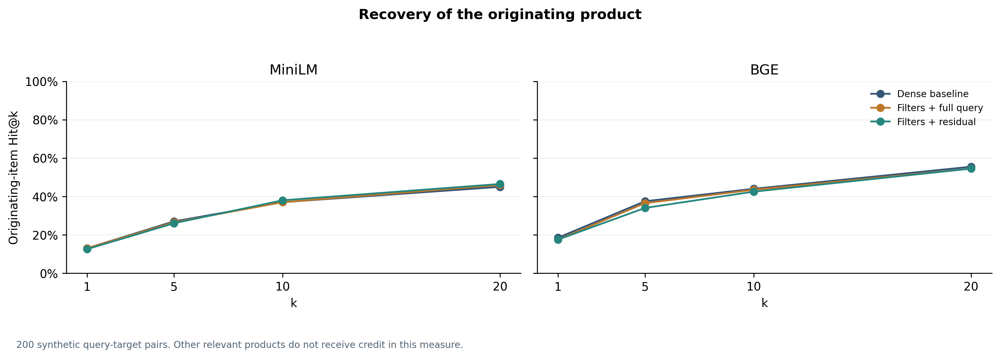

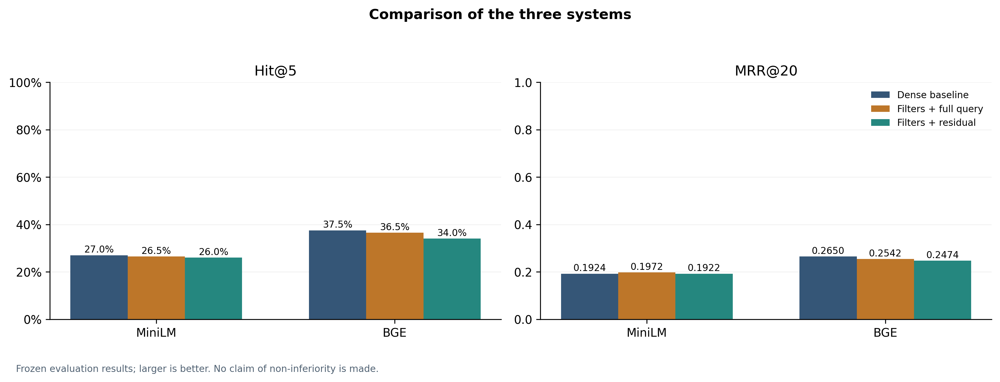

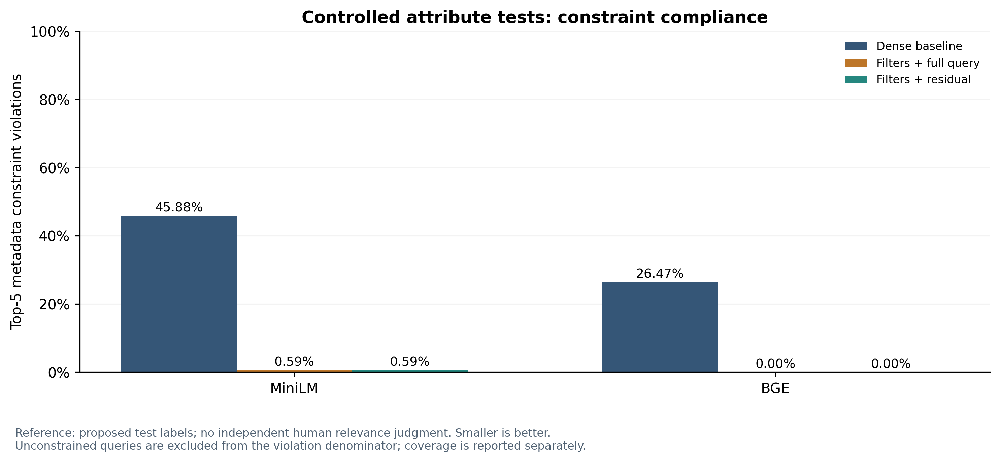

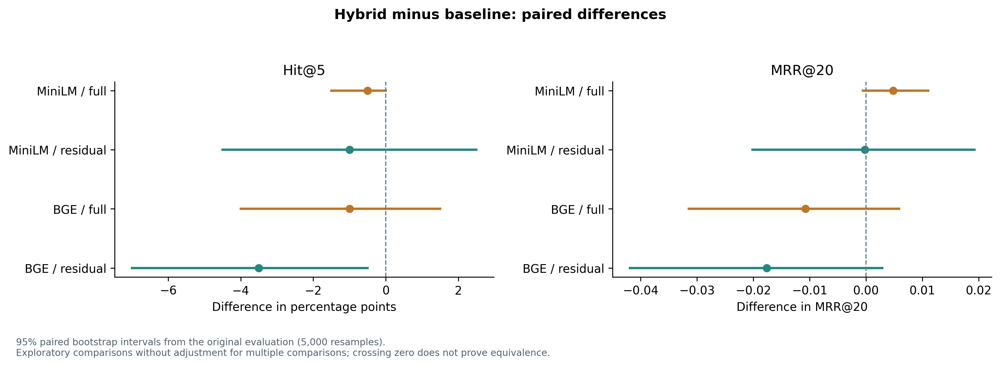

In [ ]:
# Registro estático da execução presente no arquivo original.
# A implementação dos painéis vinha de um script externo não anexado.

### Exemplos de produtos recuperados

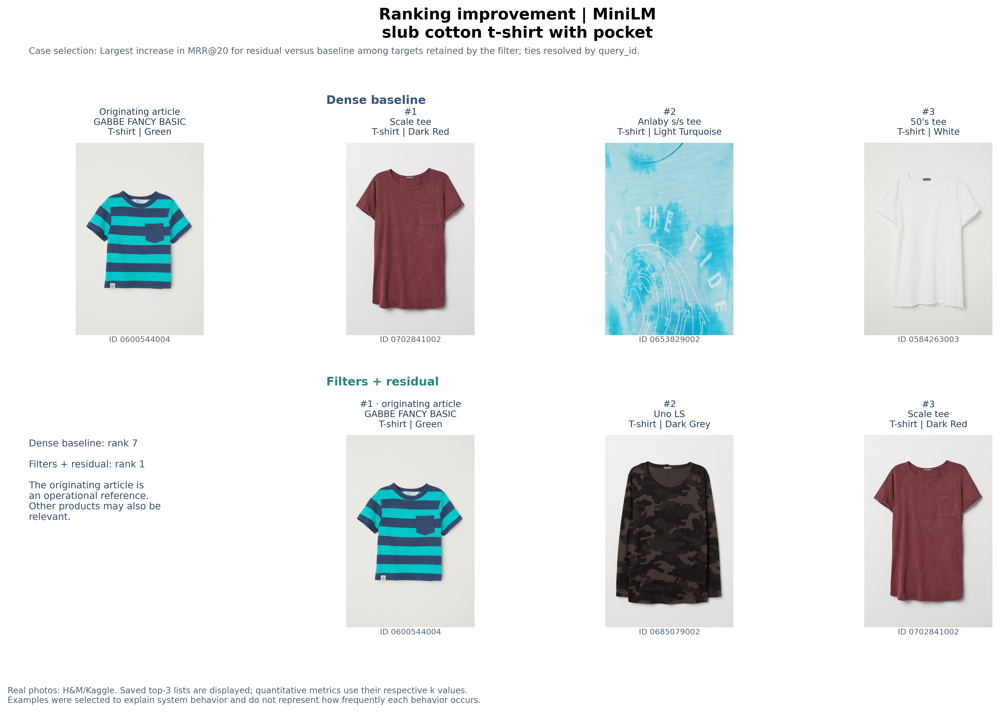

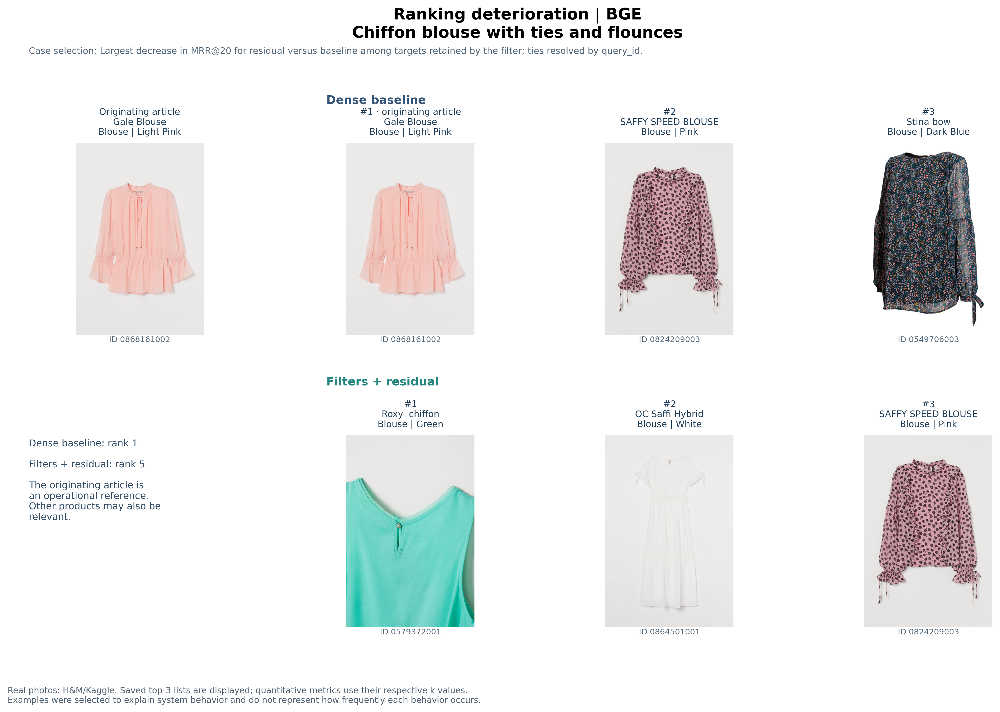

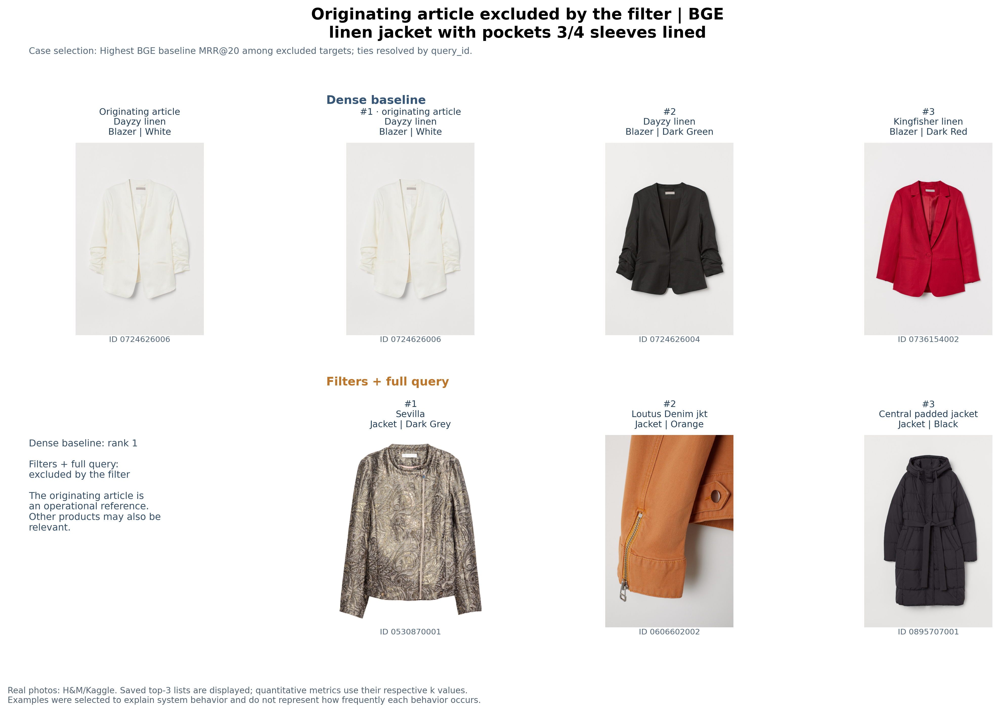

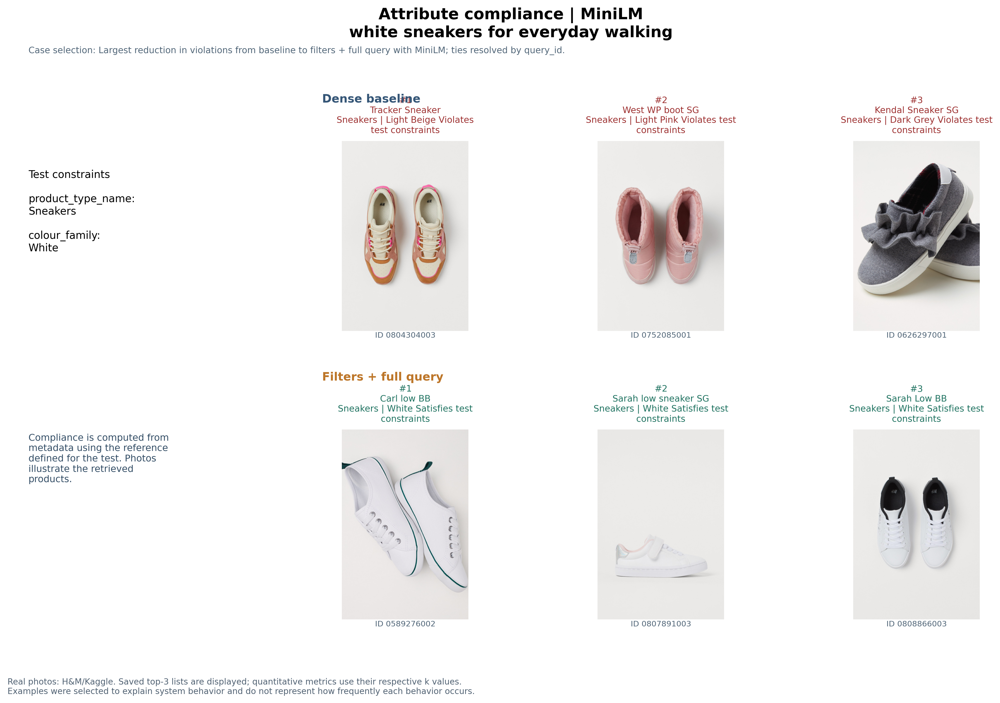

In [ ]:
# Registro estático da execução presente no arquivo original.
# A implementação dos painéis vinha de um script externo não anexado.